# Session 09 – Python code from the session notes

This notebook contains the code shown in the Session 9 notes, with the output it produced. It uses the same packages and functions as Tutorial 9.

The data are typed in directly: the impurity example from Brooks, Chapter 9 (four batches per supplier) and the API response-time example used to illustrate Welch's ANOVA. Tutorial 9 uses the larger data set `supplier_impurity.csv` instead.

Page numbers refer to the Session 9 notes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from scipy.stats import f, probplot
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print(statsmodels.__version__)

0.14.6


## 1. Worked example: impurity from three suppliers (notes page 9)

Results in the notes: SS 28.667 / 9.000, df 2 / 9, F = 14.33, p = 0.0016.

In [2]:
df = pd.DataFrame({
    "supplier": ["A"]*4 + ["B"]*4 + ["C"]*4,
    "impurity_mg_kg": [8, 9, 7, 10, 12, 11, 13, 12,
                       9, 10, 8, 9],
})
model = ols("impurity_mg_kg ~ C(supplier)", data=df).fit()
print(anova_lm(model, typ=2))       # SS, df, F, p
print(round(f.sf(14.333, 2, 9), 4))   # step 4: P(F >= 14.333)

                sum_sq   df          F    PR(>F)
C(supplier)  28.666667  2.0  14.333333  0.001593
Residual      9.000000  9.0        NaN       NaN
0.0016


## 2. QQ-plot of the residuals (notes page 10)

The residuals $e_{ij} = x_{ij} - \bar x_i$, not the raw impurity values.

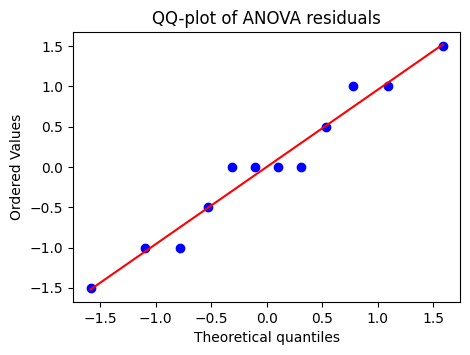

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.5))
probplot(model.resid, dist="norm", plot=ax)   # e_ij
ax.set_title("QQ-plot of ANOVA residuals")
plt.show()     # residuals, NOT df["impurity_mg_kg"]

## 3. Welch example: API response times (notes page 12)

Results in the notes: classical F = 0.85, p = 0.4424; Welch F = 15.40, df = (2, 6.87), p = 0.0029.

In [4]:
times = pd.DataFrame({
    "config": ["A"]*10 + ["B"]*4 + ["C"]*10,
    "time_ms": [118, 121, 120, 119, 122,
                120, 121, 119, 120, 120,
                112, 135, 104, 129,
                123, 124, 122, 123, 125,
                121, 123, 124, 122, 123],
})
print(times.groupby("config")["time_ms"].agg(n="size", mean="mean", std="std"))

         n   mean        std
config                      
A       10  120.0   1.154701
B        4  120.0  14.445299
C       10  123.0   1.154701


In [5]:
classical = ols("time_ms ~ C(config)", data=times).fit()
print(anova_lm(classical, typ=2))

           sum_sq    df         F    PR(>F)
C(config)    52.5   2.0  0.848077  0.442388
Residual    650.0  21.0       NaN       NaN


In [6]:
welch = anova_oneway(times["time_ms"], groups=times["config"],
                     use_var="unequal")
print(welch)

statistic = 15.40186248043778
pvalue = 0.0028928088297334696
df = (2.0, np.float64(6.869657251736614))
df_num = 2.0
df_denom = 6.869657251736614
nobs_t = 24.0
n_groups = 3
means = [120. 120. 123.]
nobs = [10.  4. 10.]
vars_ = [  1.33333333 208.66666667   1.33333333]
use_var = unequal
welch_correction = True
tuple = (np.float64(15.40186248043778), np.float64(0.0028928088297334696))


## 4. Tukey HSD for the worked example (notes page 15)

Results in the notes: B − A = 3.50 [1.53; 5.47], C − A = 0.50 [−1.47; 2.47], C − B = −3.00 [−4.97; −1.03]; adjusted p 0.0020, 0.7655, 0.0055. `meandiff` = group2 − group1.

In [7]:
tukey = pairwise_tukeyhsd(df["impurity_mg_kg"], df["supplier"],
                          alpha=0.05)
print(tukey.summary())

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B      3.5  0.002  1.5258  5.4742   True
     A      C      0.5 0.7655 -1.4742  2.4742  False
     B      C     -3.0 0.0055 -4.9742 -1.0258   True
----------------------------------------------------


## 5. Optional: effect size $\eta^2$ (notes page 15)

Results in the notes: 0.761.

In [8]:
tbl = anova_lm(model, typ=2)
eta2 = tbl.loc["C(supplier)", "sum_sq"] / tbl["sum_sq"].sum()
print(f"eta-squared = {eta2:.3f}")

eta-squared = 0.761
